In [20]:
# ============================================================
# Cell 1: 导入 + 读取 base_v3（header=0）+ 构造特征与标签
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("[warn] xgboost not installed, will skip XGBoost")

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ---------- 读取原始数据 (base_v3, 表头在第 1 排 → header=0) ----------
file_path = 'CLEAN_blockchain_dot_com_daily_data.xlsx'
df = pd.read_excel(file_path, sheet_name='base_v3', header=0)

# 列名去空格
df.columns = [str(c).strip() for c in df.columns]

print("读取到的列名:")
for i, c in enumerate(df.columns):
    print(f"  [{i}] {repr(c)}")

# 统一列名
df = df.rename(columns={
    'miners_revenue（USD）': 'miners_revenue_usd',
    'total_transaction_fees（BTC）': 'total_transaction_fees_btc',
})

# 日期列统一命名
if 'datetime' not in df.columns:
    for c in ['Date', 'date', 'Datetime', 'timestamp', 'Unnamed: 0']:
        if c in df.columns:
            df = df.rename(columns={c: 'datetime'})
            print(f"将 {repr(c)} 重命名为 'datetime'")
            break

# 日期处理
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df = df.dropna(subset=['datetime'])
df = df.sort_values('datetime').drop_duplicates('datetime', keep='last').reset_index(drop=True)

print("\n原数据日期范围:", df['datetime'].min(), "至", df['datetime'].max())
print("原始记录数:", len(df))

# ---------- 数值类型统一（处理 '1,234.56' 千分位字符串） ----------
def to_numeric_safe(s):
    if s.dtype == object:
        s = s.astype(str).str.replace(',', '', regex=False)
    return pd.to_numeric(s, errors='coerce')

num_cols = [
    'market_price_usd', 'exchange_volume_usd', 'market_cap_usd',
    'mempool_size', 'transaction_rate', 'average_block_size',
    'average_confirmation_time', 'hash_rate', 'difficulty',
    'miners_revenue_usd', 'total_transaction_fees_btc',
    # 传统指数
    'OEX_Close', 'SP500_Close', 'NASDAQ100_Close', 'DOW_Close',
    'RUSSELL2000_Close', 'VIX_Close', 'DXY_Close', 'US10Y_Close', 'GOLD_Close',
    'OEX_Close_FFill', 'SP500_Close_FFill', 'NASDAQ100_Close_FFill',
    'DOW_Close_FFill', 'RUSSELL2000_Close_FFill', 'VIX_Close_FFill',
    'DXY_Close_FFill', 'US10Y_Close_FFill', 'GOLD_Close_FFill',
    # 加密货币
    'ETH_Close', 'BNB_Close', 'XRP_Close', 'BCH_Close',
    'LTC_Close', 'ADA_Close', 'LINK_Close', 'DOGE_Close',
]
for col in num_cols:
    if col in df.columns:
        df[col] = to_numeric_safe(df[col])

df.loc[df['exchange_volume_usd'] == 0, 'exchange_volume_usd'] = np.nan

# ---------- 标签 ----------
df['target'] = (df['market_price_usd'] > df['market_price_usd'].shift(1)).astype(int)

# ---------- 原始 BTC 市场特征 ----------
df['return_1d']      = df['market_price_usd'].pct_change()
df['cum_return_7d']  = df['market_price_usd'].pct_change().rolling(7).sum()
df['volatility_7d']  = df['market_price_usd'].pct_change().rolling(7).std()
df['volume_change']  = np.log(df['exchange_volume_usd'] / df['exchange_volume_usd'].shift(1))

# ---------- 新增市场特征：传统指数收益率（用 FFill 版本，避免周末缺失） ----------
traditional_map = {
    'OEX_Close_FFill':         'OEX_ret',
    'SP500_Close_FFill':       'SP500_ret',
    'NASDAQ100_Close_FFill':   'NASDAQ100_ret',
    'DOW_Close_FFill':         'DOW_ret',
    'RUSSELL2000_Close_FFill': 'RUSSELL2000_ret',
    'VIX_Close_FFill':         'VIX_ret',
    'DXY_Close_FFill':         'DXY_ret',
    'US10Y_Close_FFill':       'US10Y_ret',
    'GOLD_Close_FFill':        'GOLD_ret',
}
for src, dst in traditional_map.items():
    if src in df.columns:
        df[dst] = df[src].pct_change()
    else:
        print(f"[warn] missing column: {src}")

# ---------- 新增市场特征：加密货币收益率（7×24 交易） ----------
crypto_map = {
    'ETH_Close':  'ETH_ret',
    'BNB_Close':  'BNB_ret',
    'XRP_Close':  'XRP_ret',
    'BCH_Close':  'BCH_ret',
    'LTC_Close':  'LTC_ret',
    'ADA_Close':  'ADA_ret',
    'LINK_Close': 'LINK_ret',
    'DOGE_Close': 'DOGE_ret',
}
for src, dst in crypto_map.items():
    if src in df.columns:
        df[dst] = df[src].pct_change()
    else:
        print(f"[warn] missing column: {src}")

# ---------- 市值收益率 ----------
if 'market_cap_usd' in df.columns:
    df['mcap_ret'] = df['market_cap_usd'].pct_change()

# ---------- 特征分组 ----------
onchain_cols = [
    'mempool_size', 'transaction_rate', 'average_block_size',
    'average_confirmation_time', 'hash_rate', 'difficulty',
    'miners_revenue_usd', 'total_transaction_fees_btc'
]

market_cols = [
    # 原始 BTC 市场
    'return_1d', 'cum_return_7d', 'volatility_7d', 'volume_change',
    # 传统指数
    'OEX_ret', 'SP500_ret', 'NASDAQ100_ret', 'DOW_ret',
    'RUSSELL2000_ret', 'VIX_ret', 'DXY_ret', 'US10Y_ret', 'GOLD_ret',
    # 加密货币
    'ETH_ret', 'BNB_ret', 'XRP_ret', 'BCH_ret',
    'LTC_ret', 'ADA_ret', 'LINK_ret', 'DOGE_ret',
    # 市值
    'mcap_ret',
]

# 只保留 df 里真实存在的列
market_cols  = [c for c in market_cols  if c in df.columns]
onchain_cols = [c for c in onchain_cols if c in df.columns]

feature_cols = market_cols + onchain_cols
print(f"\nMarket features  ({len(market_cols)}):  {market_cols}")
print(f"On-chain features ({len(onchain_cols)}): {onchain_cols}")

# ---------- 滞后一阶 + dropna ----------
X = df[['datetime'] + feature_cols].copy()
X = X.set_index('datetime').shift(1)
y = df.set_index('datetime')['target']

data = pd.concat([X, y], axis=1).dropna()
X = data[feature_cols]
y = data['target']

print(f"\n有效样本数: {len(data)}")
print("日期范围:", data.index.min(), "至", data.index.max())
print("标签分布:\n", y.value_counts(normalize=True))

读取到的列名:
  [0] 'datetime'
  [1] 'mempool_size'
  [2] 'transaction_rate'
  [3] 'market_cap_usd'
  [4] 'average_block_size'
  [5] 'market_price_usd'
  [6] 'exchange_volume_usd'
  [7] 'average_confirmation_time'
  [8] 'hash_rate'
  [9] 'difficulty'
  [10] 'miners_revenue_usd'
  [11] 'total_transaction_fees_btc'
  [12] 'next_day_up'
  [13] 'OEX_Close'
  [14] 'SP500_Close'
  [15] 'NASDAQ100_Close'
  [16] 'DOW_Close'
  [17] 'RUSSELL2000_Close'
  [18] 'VIX_Close'
  [19] 'DXY_Close'
  [20] 'US10Y_Close'
  [21] 'GOLD_Close'
  [22] 'ETH_Close'
  [23] 'BNB_Close'
  [24] 'XRP_Close'
  [25] 'BCH_Close'
  [26] 'LTC_Close'
  [27] 'ADA_Close'
  [28] 'LINK_Close'
  [29] 'DOGE_Close'
  [30] 'OEX_Close_FFill'
  [31] 'SP500_Close_FFill'
  [32] 'NASDAQ100_Close_FFill'
  [33] 'DOW_Close_FFill'
  [34] 'RUSSELL2000_Close_FFill'
  [35] 'VIX_Close_FFill'
  [36] 'DXY_Close_FFill'
  [37] 'US10Y_Close_FFill'
  [38] 'GOLD_Close_FFill'

原数据日期范围: 2018-01-01 00:00:00 至 2023-09-02 00:00:00
原始记录数: 2071

Market features  

In [2]:
# ============================================================
# Cell 2 (Block A): 通用滚动预测 —— 只输出概率，阈值后处理
# ============================================================
def rolling_forecast_probs(X, y, model, start_date, end_date,
                           window_days=90, min_train=72):
    """
    滚动训练 + 一步向前预测，只返回每日的 y_true / y_prob。
    window_days: 训练窗口（自然日）。7=1周, 15=半月, 30=1月, 90=3月...
    min_train:   窗口里最少有效样本数，不足则跳过该预测日。
    """
    pred_dates = X.loc[start_date:end_date].index
    results = []
    for D in pred_dates:
        if D not in X.index:
            continue
        window_start = D - pd.Timedelta(days=window_days) - pd.Timedelta(days=1)
        window_end   = D - pd.Timedelta(days=1)
        train_idx    = (X.index >= window_start) & (X.index <= window_end)
        X_train, y_train = X.loc[train_idx], y.loc[train_idx]
        if len(X_train) < min_train:
            continue
        model.fit(X_train, y_train)
        X_test = X.loc[[D]]
        y_prob = model.predict_proba(X_test)[0, 1] if hasattr(model, "predict_proba") else np.nan
        results.append({'date': D, 'y_true': y.loc[D], 'y_prob': y_prob})
    return pd.DataFrame(results).set_index('date')


def apply_threshold(probs, threshold):
    out = probs.copy()
    out['y_pred'] = (out['y_prob'] >= threshold).astype(int)
    return out


def quick_metrics(results):
    y_true = results['y_true']
    y_pred = results['y_pred']
    y_prob = results['y_prob']
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1':       f1_score(y_true, y_pred, zero_division=0),  # ★ 防止 NaN
        'ROC-AUC':  roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
        'N':        len(results),
    }

In [3]:
# ============================================================
# Cell 3 (Block B): 模型工厂（统一为 Pipeline）
# ============================================================
def make_knn():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('clf',     KNeighborsClassifier(n_neighbors=5))
    ])

def make_lr():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('clf',     LogisticRegression(C=1.0, penalty='l2', class_weight='balanced',
                                       max_iter=1000, random_state=42))
    ])

def make_rf():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf',     RandomForestClassifier(n_estimators=300, max_depth=5,
                                           min_samples_split=10, min_samples_leaf=4,
                                           max_features='sqrt', class_weight='balanced',
                                           random_state=42, n_jobs=-1))
    ])

def make_dt():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf',     DecisionTreeClassifier(max_depth=5, min_samples_leaf=4,
                                           class_weight='balanced', random_state=42))
    ])

def make_svm():
    # LinearSVC 无 predict_proba，需 CalibratedClassifierCV 包装
    # 小窗口下可能 <cv 类数，用 cv='prefit' 之外的方案：显式给 cv=2 并捕获异常
    base = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000, random_state=42)
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('clf',     CalibratedClassifierCV(base, cv=2))   # 从 3 降到 2，减小最小样本要求
    ])

def make_ada():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf',     AdaBoostClassifier(n_estimators=100, learning_rate=0.5,
                                       random_state=42))
    ])

def make_xgb():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clf',     XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                                  eval_metric='logloss', verbosity=0,
                                  random_state=42, n_jobs=-1))
    ])

def make_lda():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('clf',     LinearDiscriminantAnalysis())
    ])

def make_mlp():
    # early_stopping=False 避免小样本下 sklearn 报 test_size 报错
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('clf',     MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000,
                                  random_state=42, early_stopping=False))
    ])

MODEL_FACTORY = {
    'KNN':                 make_knn,
    'Logistic Regression': make_lr,
    'Random Forest':       make_rf,
    'Decision Tree':       make_dt,
    'Linear SVM':          make_svm,
    'AdaBoost':            make_ada,
    'LDA':                 make_lda,
    'MLP':                 make_mlp,
}
if HAS_XGB:
    MODEL_FACTORY['XGBoost'] = make_xgb

print("Models to run:", list(MODEL_FACTORY.keys()))

Models to run: ['KNN', 'Logistic Regression', 'Random Forest', 'Decision Tree', 'Linear SVM', 'AdaBoost', 'LDA', 'MLP', 'XGBoost']


===== 特征重要性排名 =====
                            RF Importance  |Corr with y|
ETH_ret                           0.23996        0.58926
BCH_ret                           0.15844        0.50654
LTC_ret                           0.13357        0.55774
ADA_ret                           0.11092        0.50931
XRP_ret                           0.09223        0.42970
BNB_ret                           0.06511        0.45208
DOGE_ret                          0.04716        0.23289
mcap_ret                          0.03281        0.30319
LINK_ret                          0.03231        0.43340
cum_return_7d                     0.00717        0.03395
return_1d                         0.00672        0.07165
total_transaction_fees_btc        0.00540        0.01380
NASDAQ100_ret                     0.00518        0.19219
difficulty                        0.00514        0.04218
hash_rate                         0.00494        0.04237
RUSSELL2000_ret                   0.00480        0.17068
OEX_ret    

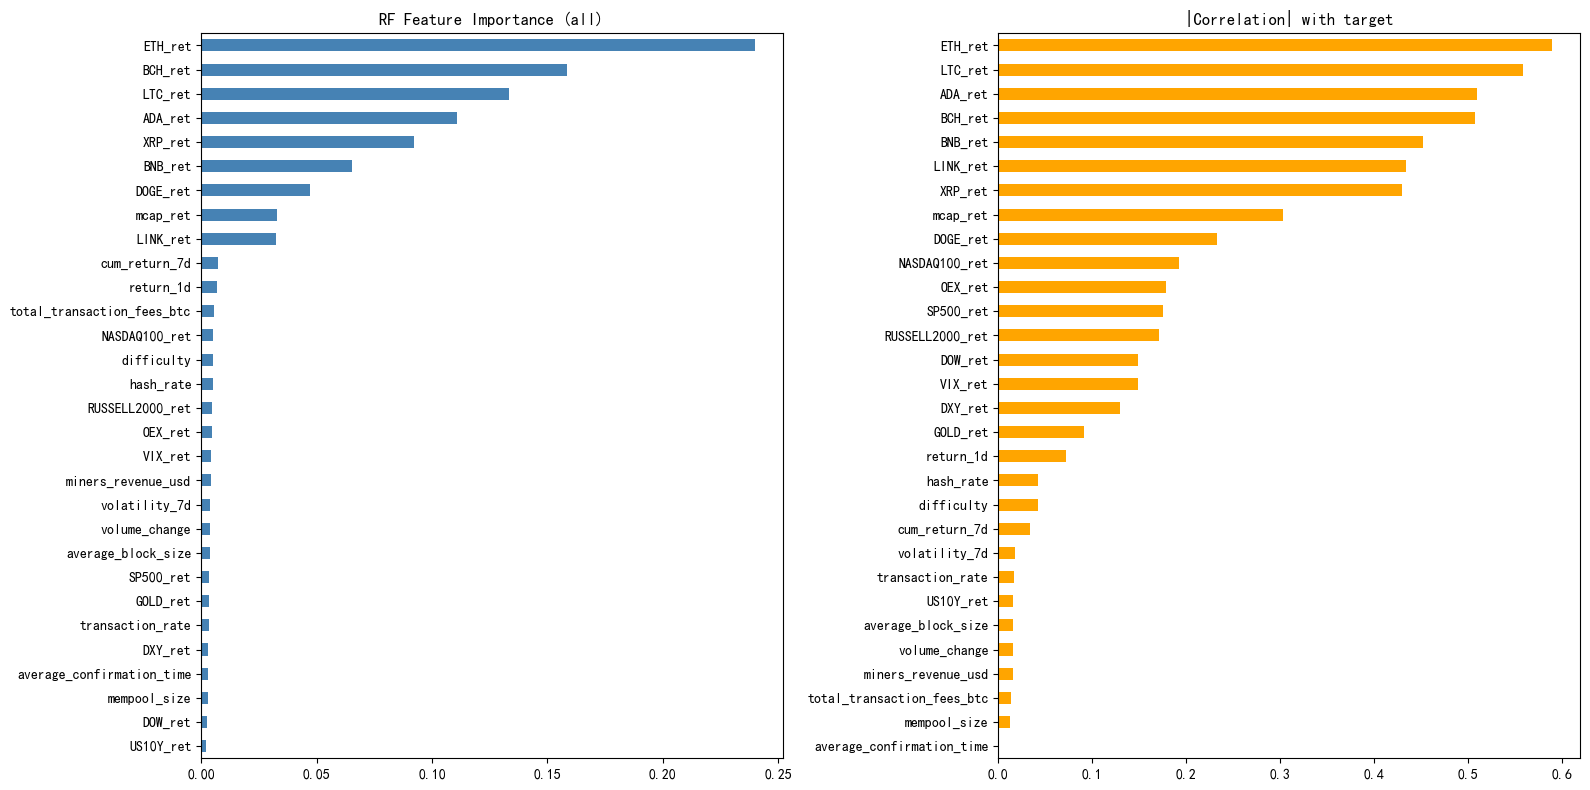


筛选后 market  (22): ['ETH_ret', 'BCH_ret', 'LTC_ret', 'ADA_ret', 'XRP_ret', 'BNB_ret', 'DOGE_ret', 'mcap_ret', 'LINK_ret', 'cum_return_7d', 'return_1d', 'NASDAQ100_ret', 'RUSSELL2000_ret', 'OEX_ret', 'VIX_ret', 'volatility_7d', 'volume_change', 'SP500_ret', 'GOLD_ret', 'DXY_ret', 'DOW_ret', 'US10Y_ret']
筛选后 onchain (8): ['total_transaction_fees_btc', 'difficulty', 'hash_rate', 'miners_revenue_usd', 'average_block_size', 'transaction_rate', 'average_confirmation_time', 'mempool_size']

特征集样本数: 2063
  Market only                22 features
  On-chain only              8 features
  Market + On-chain          30 features


In [4]:
# ============================================================
# Cell 3.5: 特征重要性排序 + Top-K 筛选 + 生成 FEATURE_SETS
# ============================================================
rf_rank = RandomForestClassifier(
    n_estimators=300, max_depth=5, min_samples_split=10,
    min_samples_leaf=4, max_features='sqrt',
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_rank.fit(X, y)

imp = pd.Series(rf_rank.feature_importances_, index=feature_cols)
imp = imp.sort_values(ascending=False)

corr_with_target = X.apply(lambda s: s.corr(y)).abs().sort_values(ascending=False)

rank_df = pd.DataFrame({
    'RF Importance': imp,
    '|Corr with y|': corr_with_target,
}).sort_values('RF Importance', ascending=False)

print("===== 特征重要性排名 =====")
print(rank_df.round(5))

# 可视化
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
imp.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('RF Feature Importance (all)')
axes[0].invert_yaxis()

corr_with_target.plot(kind='barh', ax=axes[1], color='orange')
axes[1].set_title('|Correlation| with target')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('feature_importance_ranking.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------- Top-K 筛选 ----------
TOP_K_MARKET  = 22
TOP_K_ONCHAIN = 8

market_ranked  = [c for c in imp.index if c in market_cols]
onchain_ranked = [c for c in imp.index if c in onchain_cols]

market_cols_top  = market_ranked[:TOP_K_MARKET]
onchain_cols_top = onchain_ranked[:TOP_K_ONCHAIN]

print(f"\n筛选后 market  ({len(market_cols_top)}): {market_cols_top}")
print(f"筛选后 onchain ({len(onchain_cols_top)}): {onchain_cols_top}")

# ---------- 3 个特征集 ----------
X_market_only    = X[market_cols_top].copy()
X_onchain_only   = X[onchain_cols_top].copy()
X_market_onchain = X[market_cols_top + onchain_cols_top].copy()
y_cmp            = y.copy()

FEATURE_SETS = {
    'Market only':       X_market_only,
    'On-chain only':     X_onchain_only,
    'Market + On-chain': X_market_onchain,
}
print(f"\n特征集样本数: {len(y_cmp)}")
for k, v in FEATURE_SETS.items():
    print(f"  {k:25s}  {v.shape[1]} features")

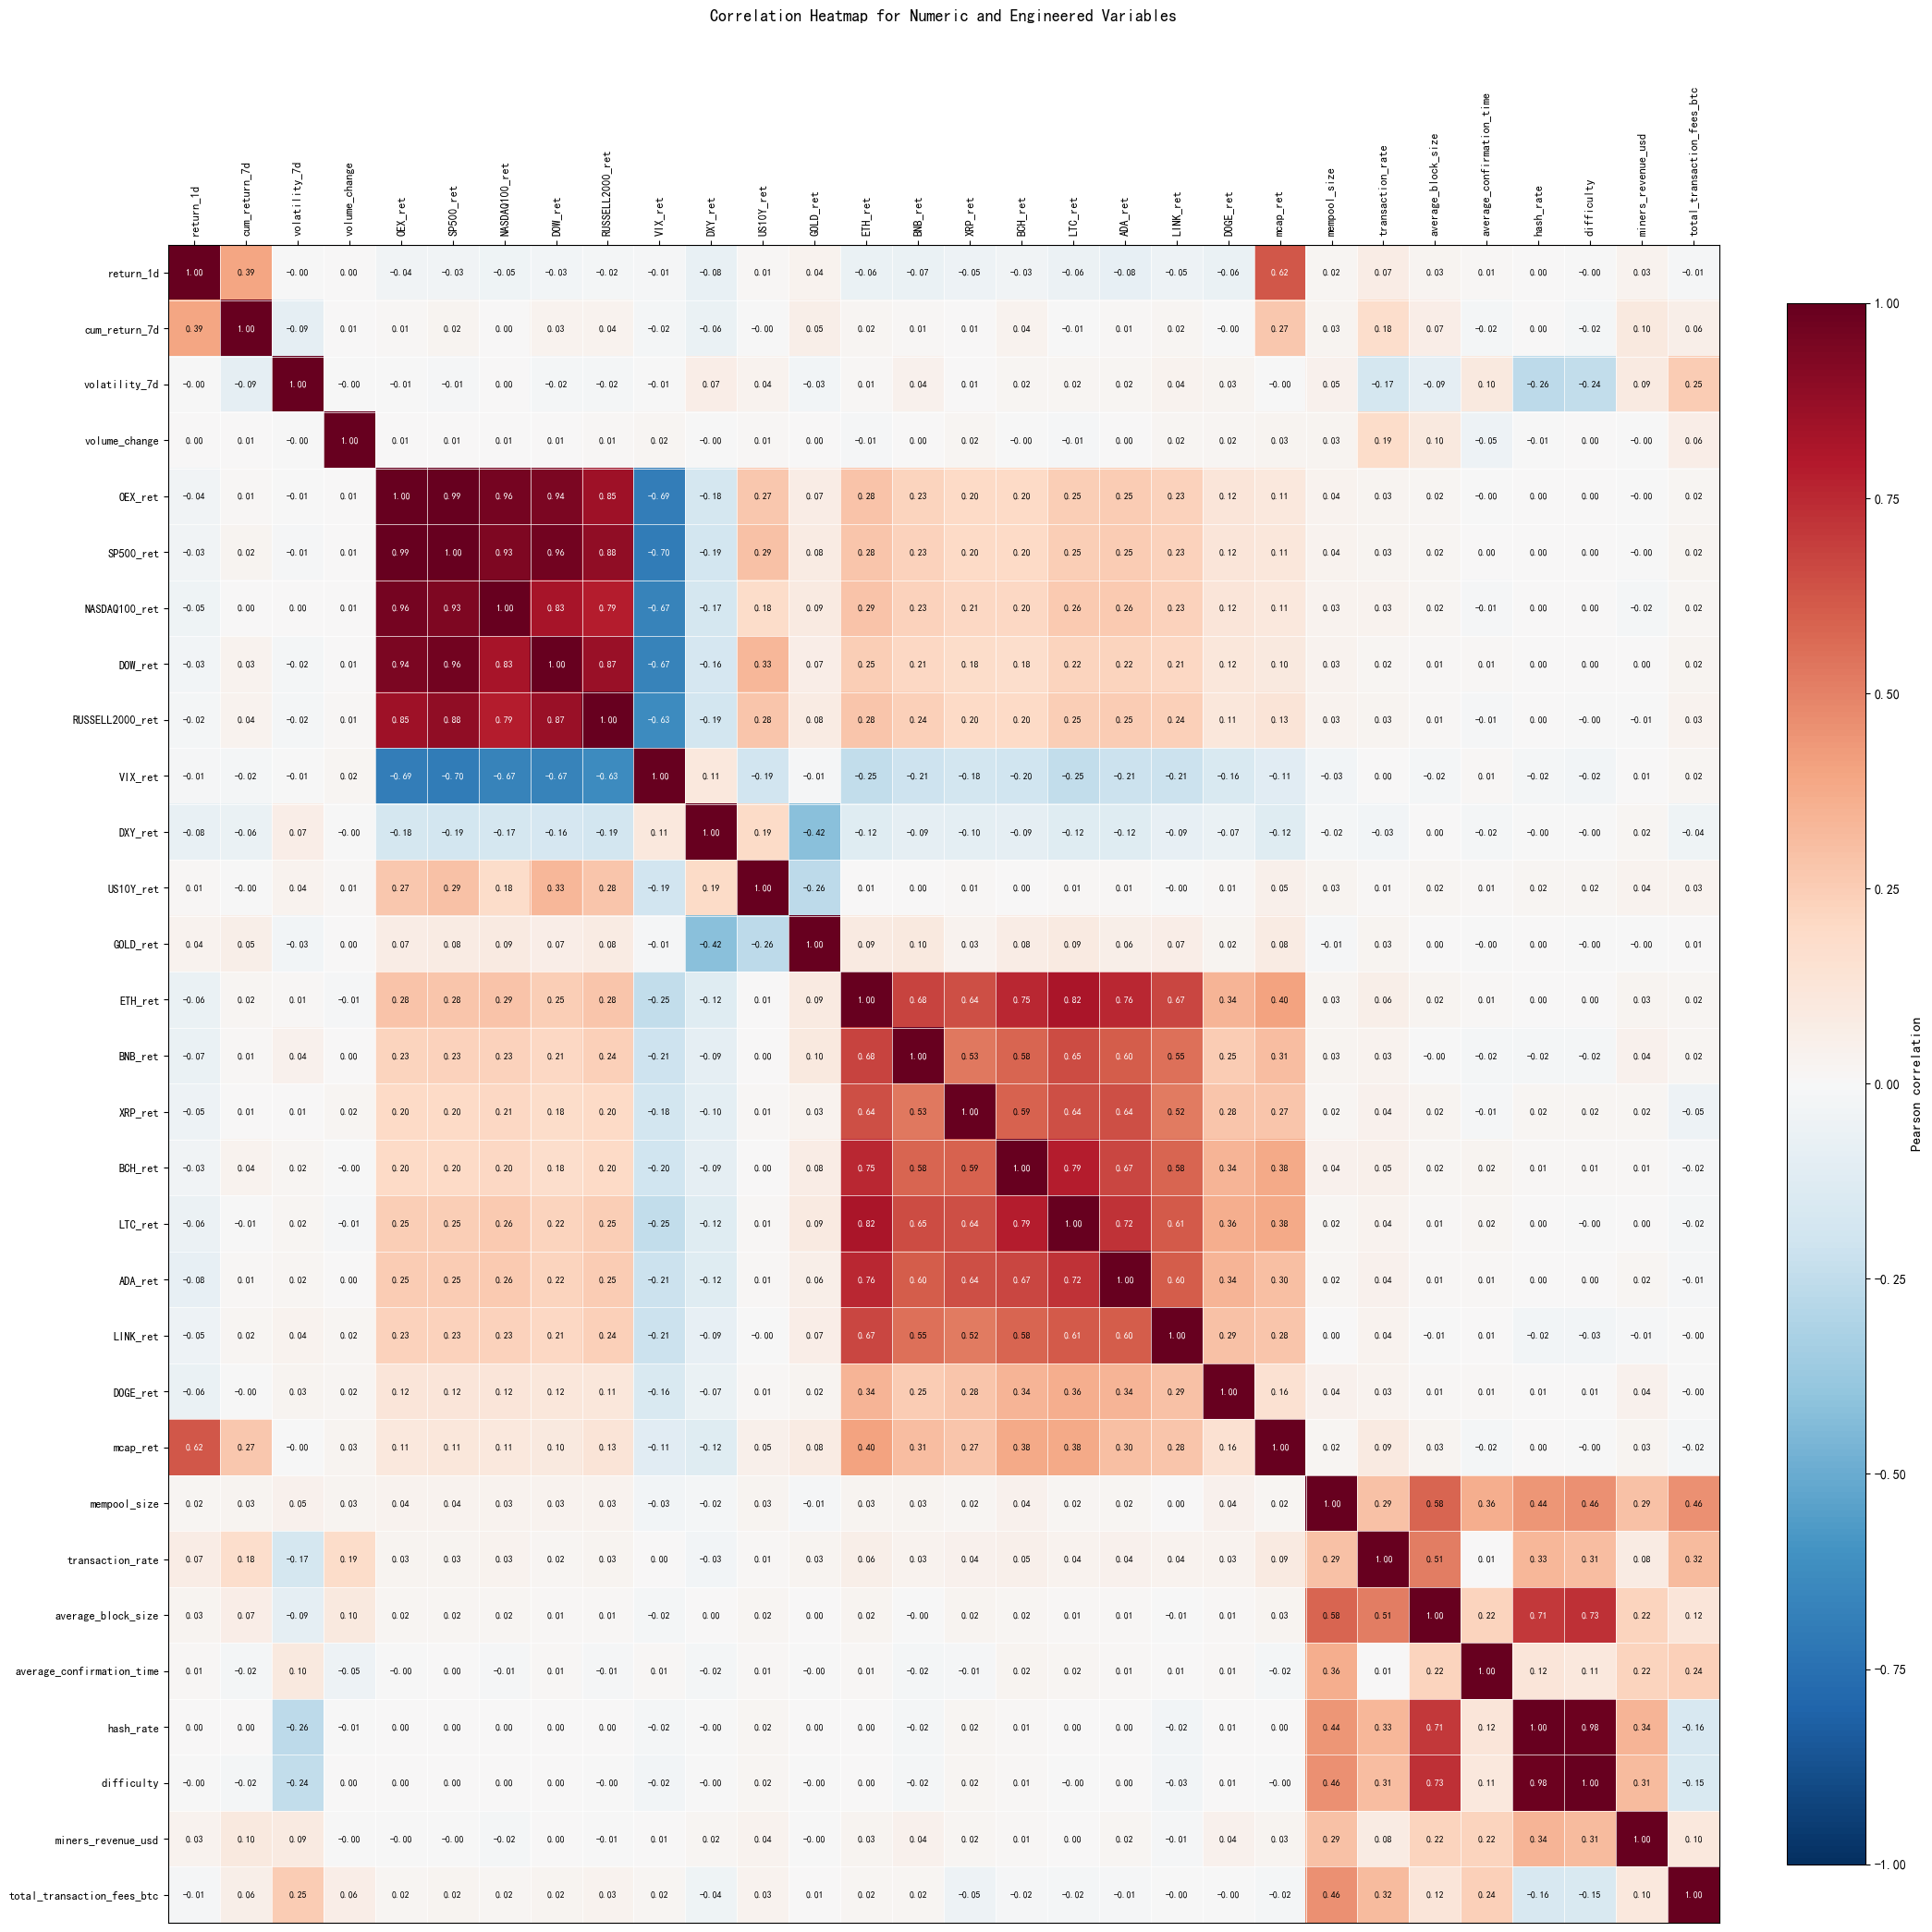


===== 高相关特征对 (|corr| > 0.7) =====
         Feature A       Feature B  Corr
           OEX_ret       SP500_ret 0.993
         hash_rate      difficulty 0.983
         SP500_ret         DOW_ret 0.961
           OEX_ret   NASDAQ100_ret 0.957
           OEX_ret         DOW_ret 0.941
         SP500_ret   NASDAQ100_ret 0.934
         SP500_ret RUSSELL2000_ret 0.885
           DOW_ret RUSSELL2000_ret 0.866
           OEX_ret RUSSELL2000_ret 0.849
     NASDAQ100_ret         DOW_ret 0.827
           ETH_ret         LTC_ret 0.816
     NASDAQ100_ret RUSSELL2000_ret 0.789
           BCH_ret         LTC_ret 0.786
           ETH_ret         ADA_ret 0.757
           ETH_ret         BCH_ret 0.755
average_block_size      difficulty 0.732
           LTC_ret         ADA_ret 0.723
average_block_size       hash_rate 0.706


In [5]:
# ============================================================
# Cell 3.6 (新增): 特征相关性热力图
#   风格：红蓝 diverging 配色 + 单元格数值 + 旋转标签
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------- 1) 选择要画相关性的特征 ----------
# 用全部特征；也可以只用筛选后的 Top-K
CORR_FEATURES = feature_cols            # 全部 30 个
# CORR_FEATURES = market_cols_top + onchain_cols_top   # 只用 Top-16

# 从数据里取出对应列，去空
corr_data = X[CORR_FEATURES].dropna()

# ---------- 2) 计算 Pearson 相关系数矩阵 ----------
corr_matrix = corr_data.corr(method='pearson')

# ---------- 3) 绘图 ----------
n = len(CORR_FEATURES)
fig, ax = plt.subplots(figsize=(max(10, 0.7 * n), max(8, 0.7 * n)))

# 红蓝 diverging 配色：-1 深蓝，0 白，+1 深红
im = ax.imshow(corr_matrix.values,
               cmap='RdBu_r',
               vmin=-1, vmax=1,
               aspect='auto')

# 色条
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Pearson correlation', fontsize=11)

# 坐标轴
ax.set_xticks(range(n))
ax.set_xticklabels(CORR_FEATURES, rotation=90, fontsize=9)
ax.set_yticks(range(n))
ax.set_yticklabels(CORR_FEATURES, fontsize=9)

# 把 x 轴标签放到顶部
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

# ---------- 4) 在单元格里写数值 ----------
for i in range(n):
    for j in range(n):
        v = corr_matrix.values[i, j]
        # 背景越深，文字越白
        text_color = 'white' if abs(v) > 0.6 else 'black'
        ax.text(j, i, f'{v:.2f}',
                ha='center', va='center',
                fontsize=7, color=text_color)

# ---------- 5) 标题和美化 ----------
ax.set_title('Correlation Heatmap for Numeric and Engineered Variables',
             fontsize=13, fontweight='bold', pad=50)

# 让格子之间有细线分隔
ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
ax.grid(which='minor', color='white', linestyle='-', linewidth=0.5)
ax.tick_params(which='minor', length=0)

plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------- 6) 顺便打印「高相关特征对」 ----------
print("\n===== 高相关特征对 (|corr| > 0.7) =====")
pairs = []
for i in range(n):
    for j in range(i + 1, n):
        v = corr_matrix.values[i, j]
        if abs(v) > 0.7:
            pairs.append((CORR_FEATURES[i], CORR_FEATURES[j], v))

if not pairs:
    print("（没有 |corr| > 0.7 的特征对）")
else:
    pairs_df = (pd.DataFrame(pairs, columns=['Feature A', 'Feature B', 'Corr'])
                  .sort_values('Corr', key=lambda s: s.abs(), ascending=False))
    print(pairs_df.round(3).to_string(index=False))

In [6]:
# ============================================================
# Cell 4 (Block C): 参数扫描 threshold × window_days
# ============================================================
for name, Xf in FEATURE_SETS.items():
    miss = [c for c in Xf.columns if c not in X.columns]
    if miss:
        raise ValueError(f"[{name}] X 缺少以下列: {miss}")

print("Market-only 特征数:",     FEATURE_SETS['Market only'].shape[1])
print("On-chain-only 特征数:",   FEATURE_SETS['On-chain only'].shape[1])
print("Market+On-chain 特征数:", FEATURE_SETS['Market + On-chain'].shape[1])

START_DATE = '2020-01-01'
END_DATE   = '2023-08-31'

THRESHOLDS = [0.3, 0.35, 0.40, 0.45, 0.50, 0.55]

WINDOW_DAYS = [7, 15, 30, 45, 60, 90, 120, 150]
WINDOW_LABELS = {
    7: '1w', 15: '0.5m', 30: '1m', 45: '1.5m',
    60: '2m', 90: '3m', 120: '4m', 150: '5m',
}

MIN_TRAIN_RATIO = 0.8
def auto_min_train(window_days, ratio=MIN_TRAIN_RATIO):
    return max(3, int(window_days * ratio))

# ---------- 概率缓存 ----------
probs_cache = {}
print("开始滚动训练（每个组合只训练一次）...")

for feature_name, X_feat in FEATURE_SETS.items():
    for model_name, factory in MODEL_FACTORY.items():
        for w in WINDOW_DAYS:
            key = (model_name, feature_name, w)
            mt  = auto_min_train(w)
            try:
                probs_cache[key] = rolling_forecast_probs(
                    X_feat, y_cmp, factory(),
                    start_date=START_DATE, end_date=END_DATE,
                    window_days=w, min_train=mt
                )
                print(f"  [done] {key}  min_train={mt}  N={len(probs_cache[key])}")
            except Exception as e:
                print(f"  [FAIL] {key}: {e}")

# ---------- 汇总所有组合 × 所有 threshold ----------
rows = []
for (model_name, feature_name, w), probs in probs_cache.items():
    if len(probs) == 0:
        continue
    for t in THRESHOLDS:
        m = quick_metrics(apply_threshold(probs, t))
        rows.append({
            'Model': model_name,
            'Feature Set': feature_name,
            'Window': w,
            'Window Label': WINDOW_LABELS.get(w, f'{w}d'),
            'Threshold': t,
            **m,
        })

sweep_df = pd.DataFrame(rows)
print("\n===== 参数扫描结果（前 10 行）=====")
print(sweep_df.head(10))

# ---------- 最优（按 F1） ----------
best_df = (sweep_df
           .sort_values('F1', ascending=False)
           .groupby(['Model', 'Feature Set'], as_index=False)
           .first())
best_df = best_df[['Model', 'Feature Set', 'Window', 'Window Label',
                   'Threshold', 'Accuracy', 'F1', 'ROC-AUC', 'N']]
print("\n===== 最优配置 (按 F1) =====")
print(best_df.round(4))

# ---------- 最优（按 ROC-AUC） ----------
best_auc_df = (sweep_df
               .sort_values('ROC-AUC', ascending=False)
               .groupby(['Model', 'Feature Set'], as_index=False)
               .first())
best_auc_df = best_auc_df[['Model', 'Feature Set', 'Window', 'Window Label',
                           'Threshold', 'Accuracy', 'F1', 'ROC-AUC', 'N']]
print("\n===== 最优配置 (按 ROC-AUC) =====")
print(best_auc_df.round(4))

Market-only 特征数: 22
On-chain-only 特征数: 8
Market+On-chain 特征数: 30
开始滚动训练（每个组合只训练一次）...
  [FAIL] ('KNN', 'Market only', 7): index 1 is out of bounds for axis 1 with size 1
  [done] ('KNN', 'Market only', 15)  min_train=12  N=1339
  [done] ('KNN', 'Market only', 30)  min_train=24  N=1339
  [done] ('KNN', 'Market only', 45)  min_train=36  N=1339
  [done] ('KNN', 'Market only', 60)  min_train=48  N=1339
  [done] ('KNN', 'Market only', 90)  min_train=72  N=1339
  [done] ('KNN', 'Market only', 120)  min_train=96  N=1339
  [done] ('KNN', 'Market only', 150)  min_train=120  N=1339
  [FAIL] ('Logistic Regression', 'Market only', 7): This solver needs samples of at least 2 classes in the data, but the data contains only one class: 1
  [done] ('Logistic Regression', 'Market only', 15)  min_train=12  N=1339
  [done] ('Logistic Regression', 'Market only', 30)  min_train=24  N=1339
  [done] ('Logistic Regression', 'Market only', 45)  min_train=36  N=1339
  [done] ('Logistic Regression', 'Market only'

In [7]:
# ============================================================
# Cell 5 (Block D): 时间聚合 + 过滤样本过少的 period
# ============================================================
FREQ = 'M'                 # 'M' 月, 'W' 周, 'Q' 季, 'Y' 年
MIN_N_PER_PERIOD = 5       # 少于 5 天的 period 会被丢弃

time_rows = []
for _, row in best_df.iterrows():
    model_name = row['Model']
    feature    = row['Feature Set']
    w          = row['Window']
    t          = row['Threshold']
    probs      = probs_cache.get((model_name, feature, w))
    if probs is None or len(probs) == 0:
        continue

    tmp = apply_threshold(probs, t)
    tmp['correct'] = (tmp['y_true'] == tmp['y_pred']).astype(int)
    tmp['period']  = tmp.index.to_period(FREQ).astype(str)

    agg = tmp.groupby('period')['correct'].agg(['mean', 'count']).reset_index()
    agg.columns = ['Period', 'Accuracy', 'N']

    for _, r in agg.iterrows():
        time_rows.append({
            'Period':      r['Period'],
            'Model':       model_name,
            'Feature Set': feature,
            'Accuracy':    r['Accuracy'],
            'N':           r['N'],
        })

time_df = pd.DataFrame(time_rows)

print(f"过滤前 periods: {sorted(time_df['Period'].unique())}")
time_df = time_df[time_df['N'] >= MIN_N_PER_PERIOD].copy()
periods_sorted = sorted(time_df['Period'].unique())
print(f"过滤后 periods: {periods_sorted}")
print(time_df.head(50))

过滤前 periods: ['2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2020-09', '2020-10', '2020-11', '2020-12', '2021-01', '2021-02', '2021-03', '2021-04', '2021-05', '2021-06', '2021-07', '2021-08', '2021-09', '2021-10', '2021-11', '2021-12', '2022-01', '2022-02', '2022-03', '2022-04', '2022-05', '2022-06', '2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08']
过滤后 periods: ['2020-01', '2020-02', '2020-03', '2020-04', '2020-05', '2020-06', '2020-07', '2020-08', '2020-09', '2020-10', '2020-11', '2020-12', '2021-01', '2021-02', '2021-03', '2021-04', '2021-05', '2021-06', '2021-07', '2021-08', '2021-09', '2021-10', '2021-11', '2021-12', '2022-01', '2022-02', '2022-03', '2022-04', '2022-05', '2022-06', '2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04', '2023-05', '2023-06', '2023-07', '2023-08']
    

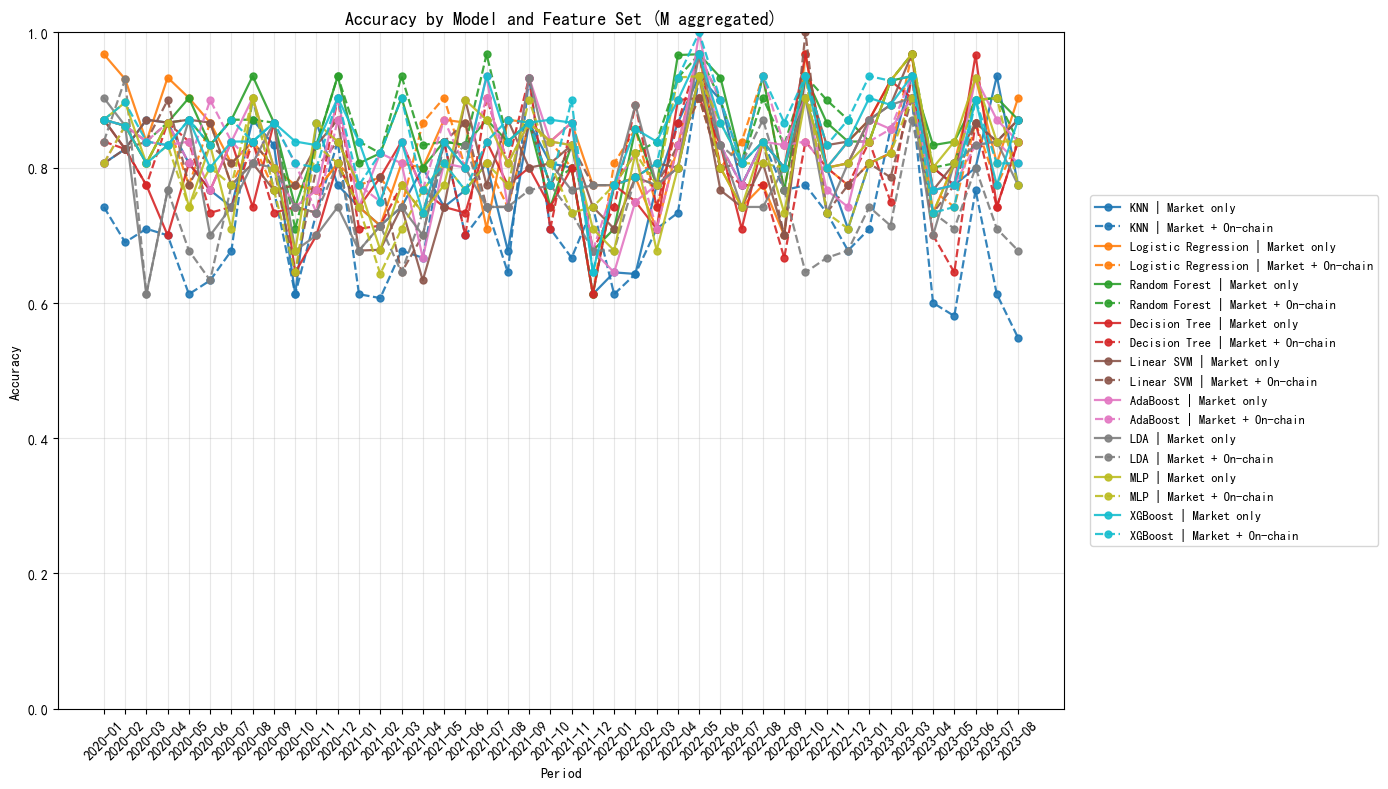

In [8]:
# ============================================================
# Cell 6 (Block E): 所有模型 × 2 特征集 → 一张图
#   颜色=模型, 线型=特征集 (实线: Market only, 虚线: Market+On-chain)
# ============================================================
models = list(MODEL_FACTORY.keys())
cmap = cm.get_cmap('tab10', len(models))
model_colors = {m: cmap(i) for i, m in enumerate(models)}

PLOT_FEATURES = ['Market only', 'Market + On-chain']

fig, ax = plt.subplots(figsize=(14, 8))

legend_handles, legend_labels = [], []
for model in models:
    for feature_name, linestyle in zip(PLOT_FEATURES, ['-', '--']):
        sub = time_df[(time_df['Model'] == model) &
                      (time_df['Feature Set'] == feature_name)]
        if sub.empty:
            continue
        s = sub.set_index('Period').reindex(periods_sorted)['Accuracy']
        line, = ax.plot(
            periods_sorted, s.values,
            marker='o', color=model_colors[model],
            linestyle=linestyle, linewidth=1.6,
            markersize=5, alpha=0.9,
            label=f"{model} | {feature_name}"
        )
        legend_handles.append(line)
        legend_labels.append(f"{model} | {feature_name}")

ax.set_title(f'Accuracy by Model and Feature Set ({FREQ} aggregated)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Period')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)
ax.legend(legend_handles, legend_labels,
          loc='center left', bbox_to_anchor=(1.02, 0.5),
          fontsize=9, ncol=1, frameon=True)

plt.tight_layout()
plt.savefig('accuracy_all_models_single_plot.png', dpi=300, bbox_inches='tight')
plt.show()

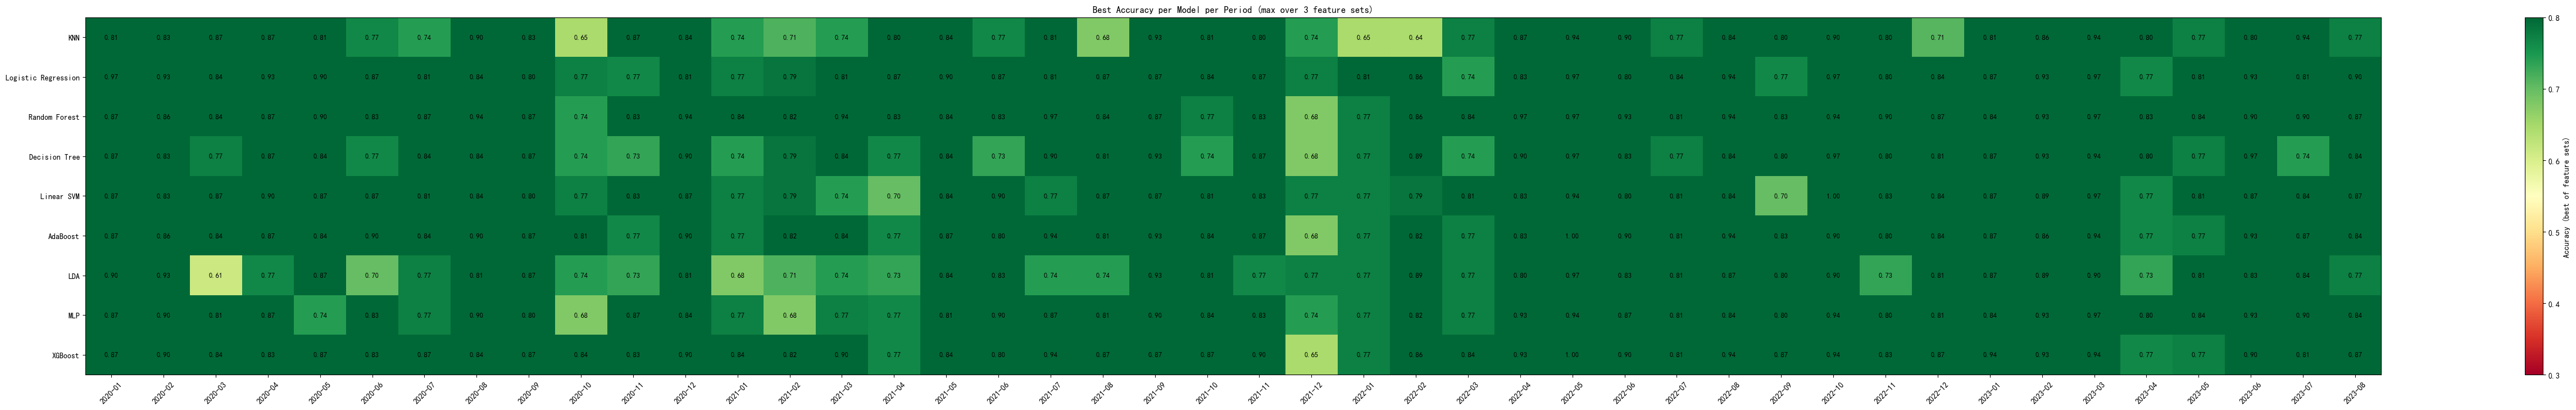

In [9]:
# ============================================================
# Block F: 热力图 —— 行=模型, 列=period, 值=3 个特征集中的 best Accuracy
# ============================================================
pivot_best = (time_df
              .groupby(['Model', 'Period'], as_index=False)['Accuracy']
              .max()
              .pivot(index='Model', columns='Period', values='Accuracy'))
pivot_best = pivot_best.reindex(columns=periods_sorted)
pivot_best = pivot_best.loc[[m for m in models if m in pivot_best.index]]

fig, ax = plt.subplots(figsize=(max(8, 1.2 * len(periods_sorted)),
                               0.6 * len(pivot_best) + 2))
im = ax.imshow(pivot_best.values, aspect='auto', cmap='RdYlGn', vmin=0.3, vmax=0.8)
plt.colorbar(im, ax=ax, label='Accuracy (best of feature sets)')

ax.set_xticks(range(len(pivot_best.columns)))
ax.set_xticklabels(pivot_best.columns, rotation=45)
ax.set_yticks(range(len(pivot_best.index)))
ax.set_yticklabels(pivot_best.index)

for i in range(pivot_best.shape[0]):
    for j in range(pivot_best.shape[1]):
        v = pivot_best.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9)

ax.set_title('Best Accuracy per Model per Period (max over 3 feature sets)')
plt.tight_layout()
plt.savefig('model_best_accuracy_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

数据范围: 0.613 ~ 1.000
色标范围: 0.594 ~ 1.000


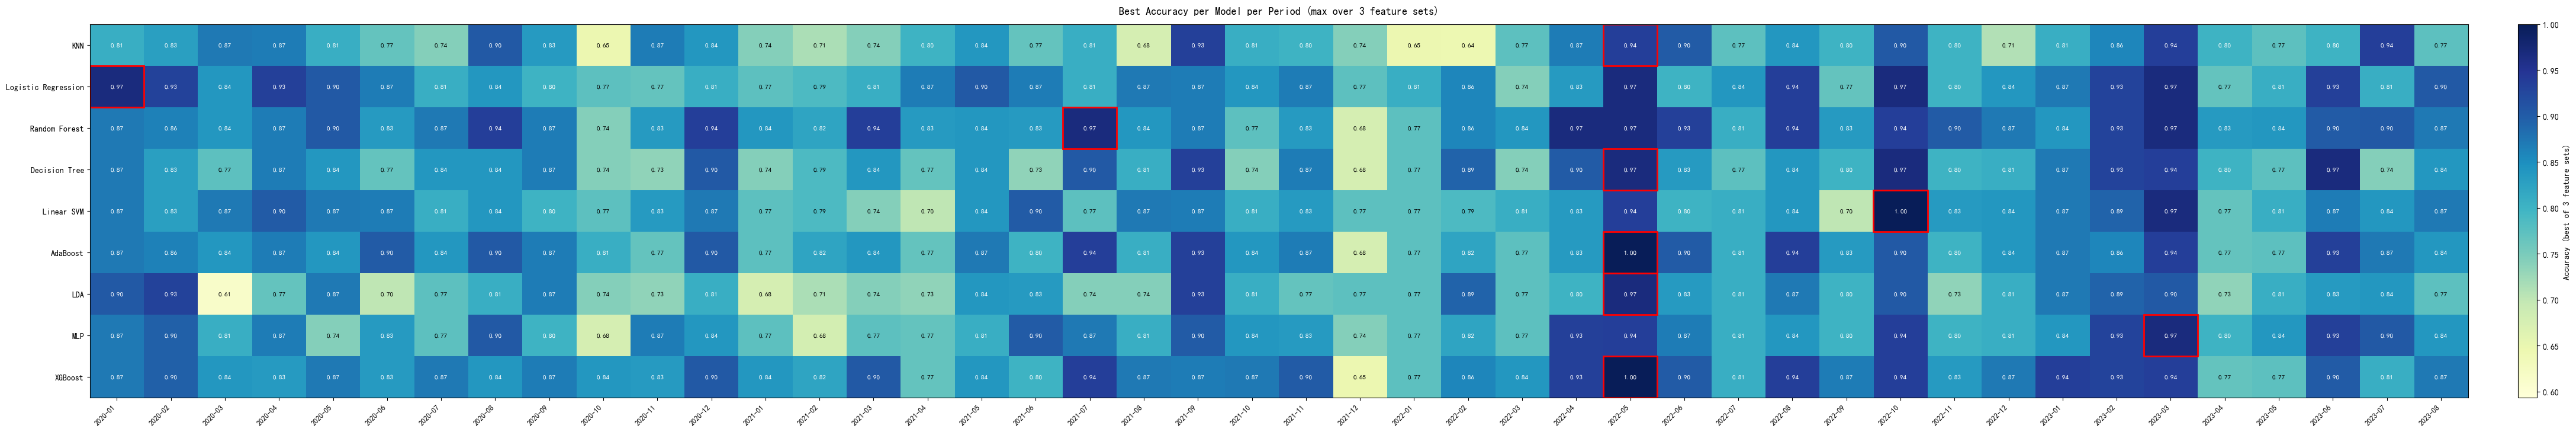

In [10]:
# ============================================================
# Block F-改进: 热力图配色优化 —— 自动适配实际数据范围
# ============================================================
# 输入：pivot_best（Block F 已经算好的 DataFrame，行=模型, 列=period）
# 输出：一张配色清晰的图，另存为 model_best_accuracy_heatmap_v2.png

import matplotlib.pyplot as plt
import numpy as np

# ---------- 1) 自动检测实际数据范围 ----------
vals = pivot_best.values.astype(float)
vmin_data = np.nanmin(vals)
vmax_data = np.nanmax(vals)

# 稍微留边距，避免最低/最高值贴死色标两端
pad = (vmax_data - vmin_data) * 0.05
vmin_plot = max(0.0, vmin_data - pad)
vmax_plot = min(1.0, vmax_data + pad)

print(f"数据范围: {vmin_data:.3f} ~ {vmax_data:.3f}")
print(f"色标范围: {vmin_plot:.3f} ~ {vmax_plot:.3f}")

# ---------- 2) 选择配色 ----------
# 可选方案：
#   'RdYlGn'   —— 红-黄-绿，直觉强（但当前值域下会全绿）
#   'YlGnBu'   —— 浅黄-绿-蓝，适合“越高越深”
#   'viridis'  —— 紫-蓝-绿-黄，色盲友好
#   'Blues'    —— 单色渐变，素雅
#   'coolwarm' —— 蓝-红，双色对比
#   'RdYlGn_r' —— 反转，绿色低、红色高
CMAP = 'YlGnBu'      # ★ 换成你想用的配色

fig, ax = plt.subplots(figsize=(max(12, 1.0 * len(pivot_best.columns)),
                               0.6 * len(pivot_best) + 2))
im = ax.imshow(
    vals,
    aspect='auto',
    cmap=CMAP,
    vmin=vmin_plot,
    vmax=vmax_plot,
)

# ---------- 3) 色条 ----------
cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('Accuracy (best of 3 feature sets)', fontsize=10)

# ---------- 4) 坐标轴 ----------
ax.set_xticks(range(len(pivot_best.columns)))
ax.set_xticklabels(pivot_best.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(pivot_best.index)))
ax.set_yticklabels(pivot_best.index, fontsize=10)

# ---------- 5) 单元格文字（根据背景深浅自动切换黑白） ----------
# 用“距离中位数多远”做阈值判断文字颜色
mid = (vmin_plot + vmax_plot) / 2
for i in range(pivot_best.shape[0]):
    for j in range(pivot_best.shape[1]):
        v = vals[i, j]
        if np.isnan(v):
            continue
        text_color = 'white' if v > mid else 'black'
        ax.text(j, i, f'{v:.2f}',
                ha='center', va='center',
                fontsize=8, color=text_color)

# ---------- 6) 高亮每个模型的最优 period ----------
for i in range(pivot_best.shape[0]):
    row = vals[i, :]
    if np.all(np.isnan(row)):
        continue
    j_best = int(np.nanargmax(row))
    ax.add_patch(plt.Rectangle(
        (j_best - 0.5, i - 0.5), 1, 1,
        fill=False, edgecolor='red', linewidth=2
    ))

ax.set_title('Best Accuracy per Model per Period (max over 3 feature sets)',
             fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig('model_best_accuracy_heatmap_v2.png', dpi=300, bbox_inches='tight')
plt.show()

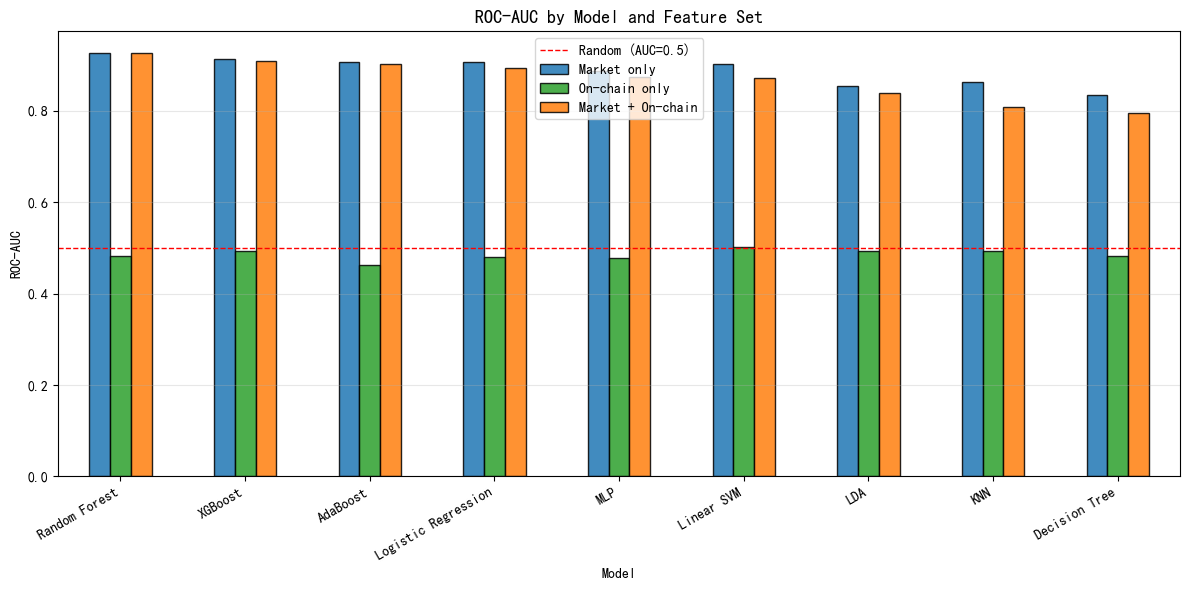


AUC 汇总：
Feature Set          Market only  On-chain only  Market + On-chain
Model                                                             
Random Forest             0.9274         0.4820             0.9270
XGBoost                   0.9125         0.4934             0.9090
AdaBoost                  0.9060         0.4635             0.9017
Logistic Regression       0.9077         0.4803             0.8931
MLP                       0.8869         0.4774             0.8733
Linear SVM                0.9021         0.5018             0.8722
LDA                       0.8538         0.4930             0.8381
KNN                       0.8623         0.4933             0.8092
Decision Tree             0.8347         0.4815             0.7944


In [11]:
# ============================================================
# Block F3: 每个 (模型, 特征集) 的 AUC 汇总条形图
# ============================================================
auc_rows = []
for _, row in best_df.iterrows():
    model_name = row['Model']
    feature    = row['Feature Set']
    w          = row['Window']
    probs = probs_cache.get((model_name, feature, w))
    if probs is None or len(probs) == 0:
        continue
    y_true = probs['y_true'].values
    y_prob = probs['y_prob'].values
    if len(np.unique(y_true)) < 2:
        continue
    auc_rows.append({
        'Model': model_name,
        'Feature Set': feature,
        'AUC': roc_auc_score(y_true, y_prob),
    })

auc_df = pd.DataFrame(auc_rows)

# 三种特征集并排
pivot = auc_df.pivot(index='Model', columns='Feature Set', values='AUC')
# 按 Market+On-chain 排序（如存在）
sort_col = 'Market + On-chain' if 'Market + On-chain' in pivot.columns else pivot.columns[0]
pivot = pivot.sort_values(sort_col, ascending=False)

# 保证三列齐全
for col in ['Market only', 'On-chain only', 'Market + On-chain']:
    if col not in pivot.columns:
        pivot[col] = np.nan
pivot = pivot[['Market only', 'On-chain only', 'Market + On-chain']]

pivot.plot(kind='bar', figsize=(12, 6),
           color=['#1f77b4', '#2ca02c', '#ff7f0e'],
           edgecolor='black', alpha=0.85)
plt.axhline(0.5, color='red', linestyle='--', linewidth=1, label='Random (AUC=0.5)')
plt.title('ROC-AUC by Model and Feature Set', fontsize=13, fontweight='bold')
plt.ylabel('ROC-AUC')
plt.xlabel('Model')
plt.xticks(rotation=30, ha='right')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('auc_bar.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nAUC 汇总：")
print(pivot.round(4))

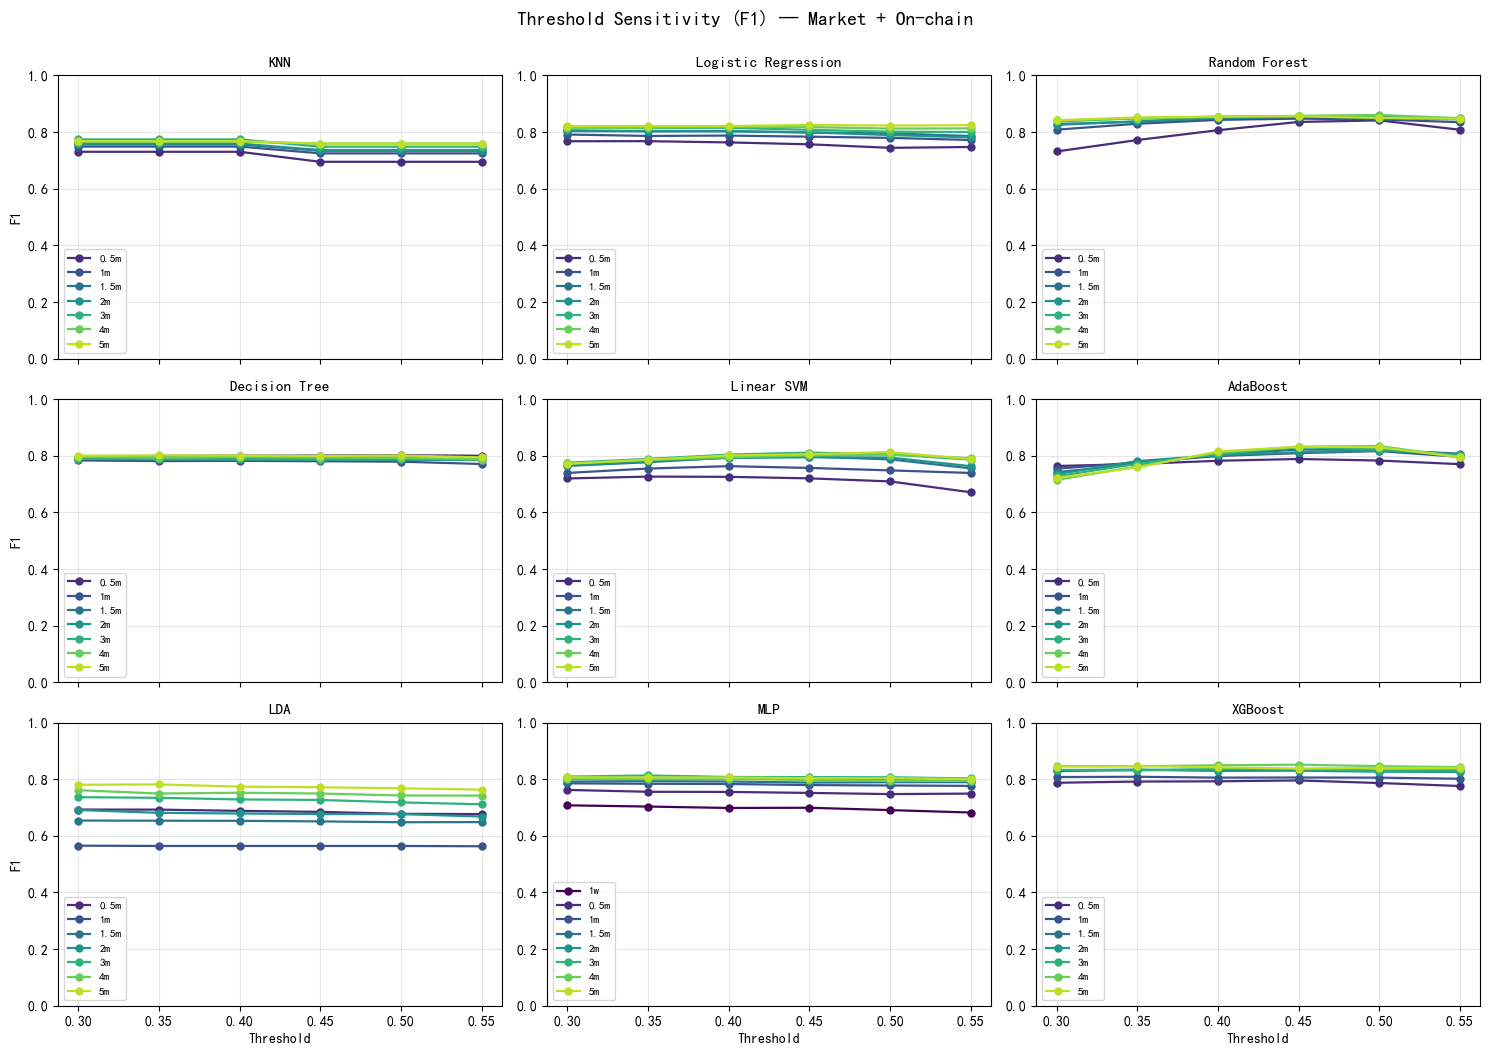

In [12]:
# ============================================================
# Block G2: threshold 对指标的影响（每个 window 一条曲线）
# ============================================================
METRIC = 'F1'
FEATURE_FOR_PLOT = 'Market + On-chain'

models = list(MODEL_FACTORY.keys())
n_cols = 3
n_rows = int(np.ceil(len(models) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(5 * n_cols, 3.5 * n_rows),
                         sharex=True, squeeze=False)

window_colors = plt.cm.viridis(np.linspace(0, 0.9, len(WINDOW_DAYS)))

for idx, model in enumerate(models):
    ax = axes[idx // n_cols][idx % n_cols]
    sub = sweep_df[(sweep_df['Model'] == model) &
                   (sweep_df['Feature Set'] == FEATURE_FOR_PLOT)]

    for w, color in zip(WINDOW_DAYS, window_colors):
        s = (sub[sub['Window'] == w]
             .sort_values('Threshold')
             .set_index('Threshold')[METRIC])
        if s.empty:
            continue
        ax.plot(s.index, s.values, marker='o',
                color=color, linewidth=1.6, markersize=5,
                label=WINDOW_LABELS.get(w, f'{w}d'))

    ax.set_title(model, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='best')
    ax.set_ylim(0, 1)

for k in range(len(models), n_rows * n_cols):
    axes[k // n_cols][k % n_cols].axis('off')

for ax in axes[-1, :]:
    ax.set_xlabel('Threshold')
for ax in axes[:, 0]:
    ax.set_ylabel(METRIC)

plt.suptitle(f'Threshold Sensitivity ({METRIC}) — {FEATURE_FOR_PLOT}',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'threshold_sensitivity_{METRIC}.png', dpi=300, bbox_inches='tight')
plt.show()

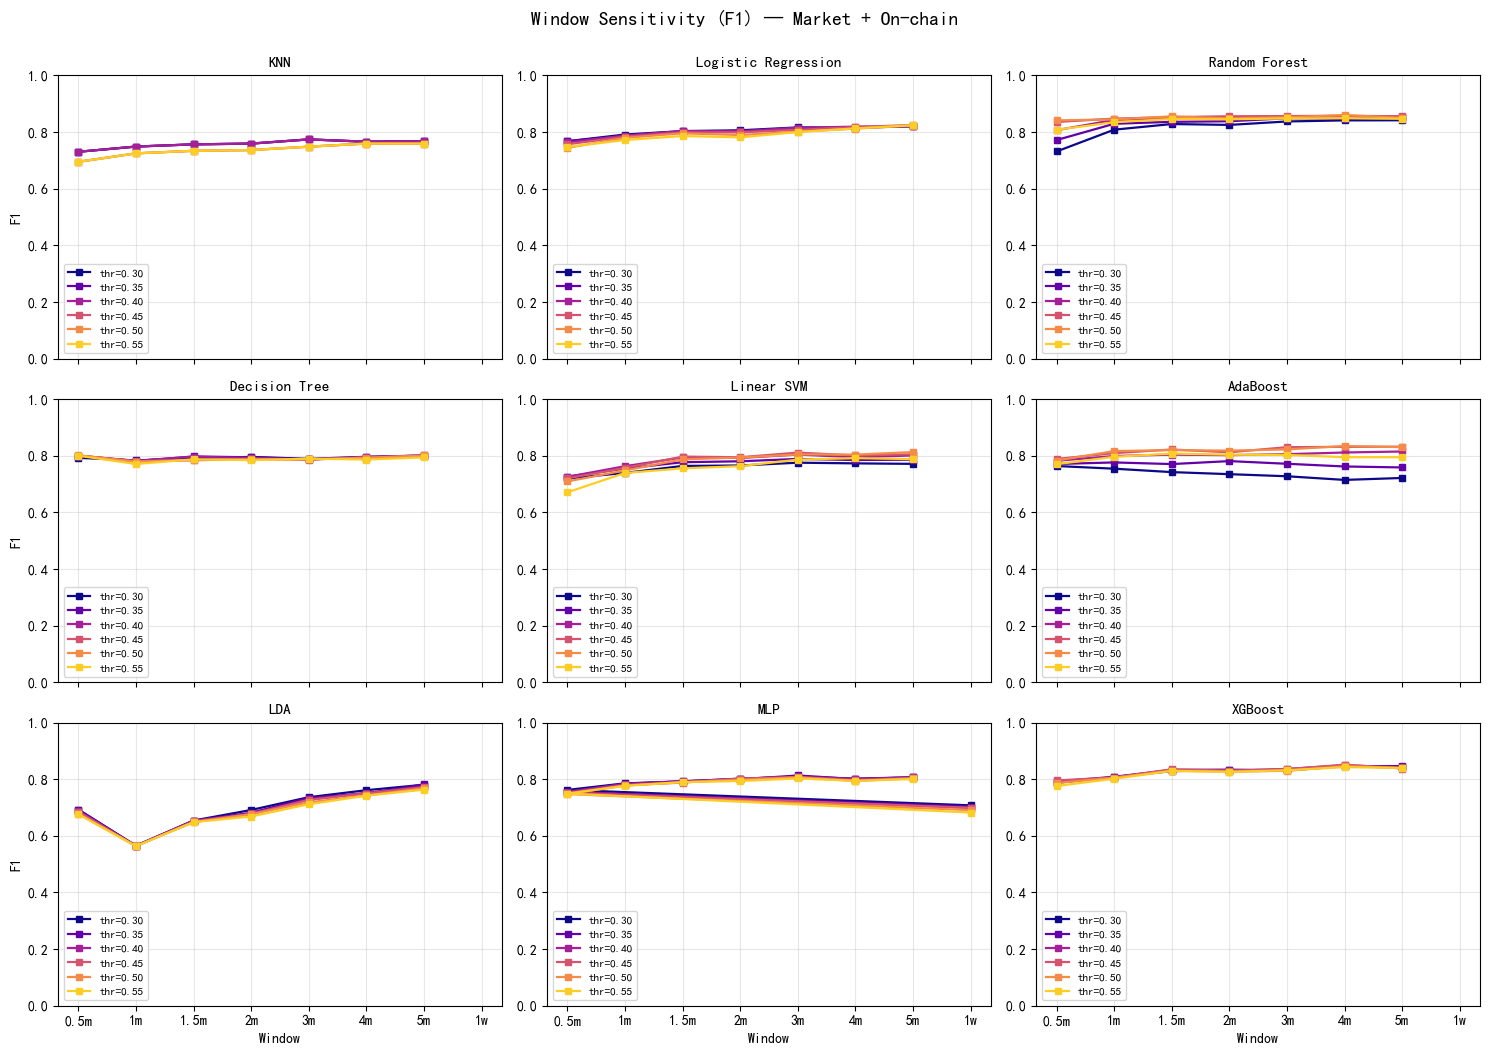

In [13]:
# ============================================================
# Block G3: window 对指标的影响（每个 threshold 一条曲线）
# ============================================================
METRIC = 'F1'
FEATURE_FOR_PLOT = 'Market + On-chain'

models = list(MODEL_FACTORY.keys())
n_cols = 3
n_rows = int(np.ceil(len(models) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(5 * n_cols, 3.5 * n_rows),
                         sharex=True, squeeze=False)

thr_colors = plt.cm.plasma(np.linspace(0, 0.9, len(THRESHOLDS)))

for idx, model in enumerate(models):
    ax = axes[idx // n_cols][idx % n_cols]
    sub = sweep_df[(sweep_df['Model'] == model) &
                   (sweep_df['Feature Set'] == FEATURE_FOR_PLOT)]

    for t, color in zip(THRESHOLDS, thr_colors):
        s = (sub[sub['Threshold'] == t]
             .sort_values('Window')
             .set_index('Window')[METRIC])
        if s.empty:
            continue
        ax.plot([WINDOW_LABELS.get(w, f'{w}d') for w in s.index],
                s.values, marker='s',
                color=color, linewidth=1.6, markersize=5,
                label=f'thr={t:.2f}')

    ax.set_title(model, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='best')
    ax.set_ylim(0, 1)

for k in range(len(models), n_rows * n_cols):
    axes[k // n_cols][k % n_cols].axis('off')

for ax in axes[-1, :]:
    ax.set_xlabel('Window')
for ax in axes[:, 0]:
    ax.set_ylabel(METRIC)

plt.suptitle(f'Window Sensitivity ({METRIC}) — {FEATURE_FOR_PLOT}',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'window_sensitivity_{METRIC}.png', dpi=300, bbox_inches='tight')
plt.show()

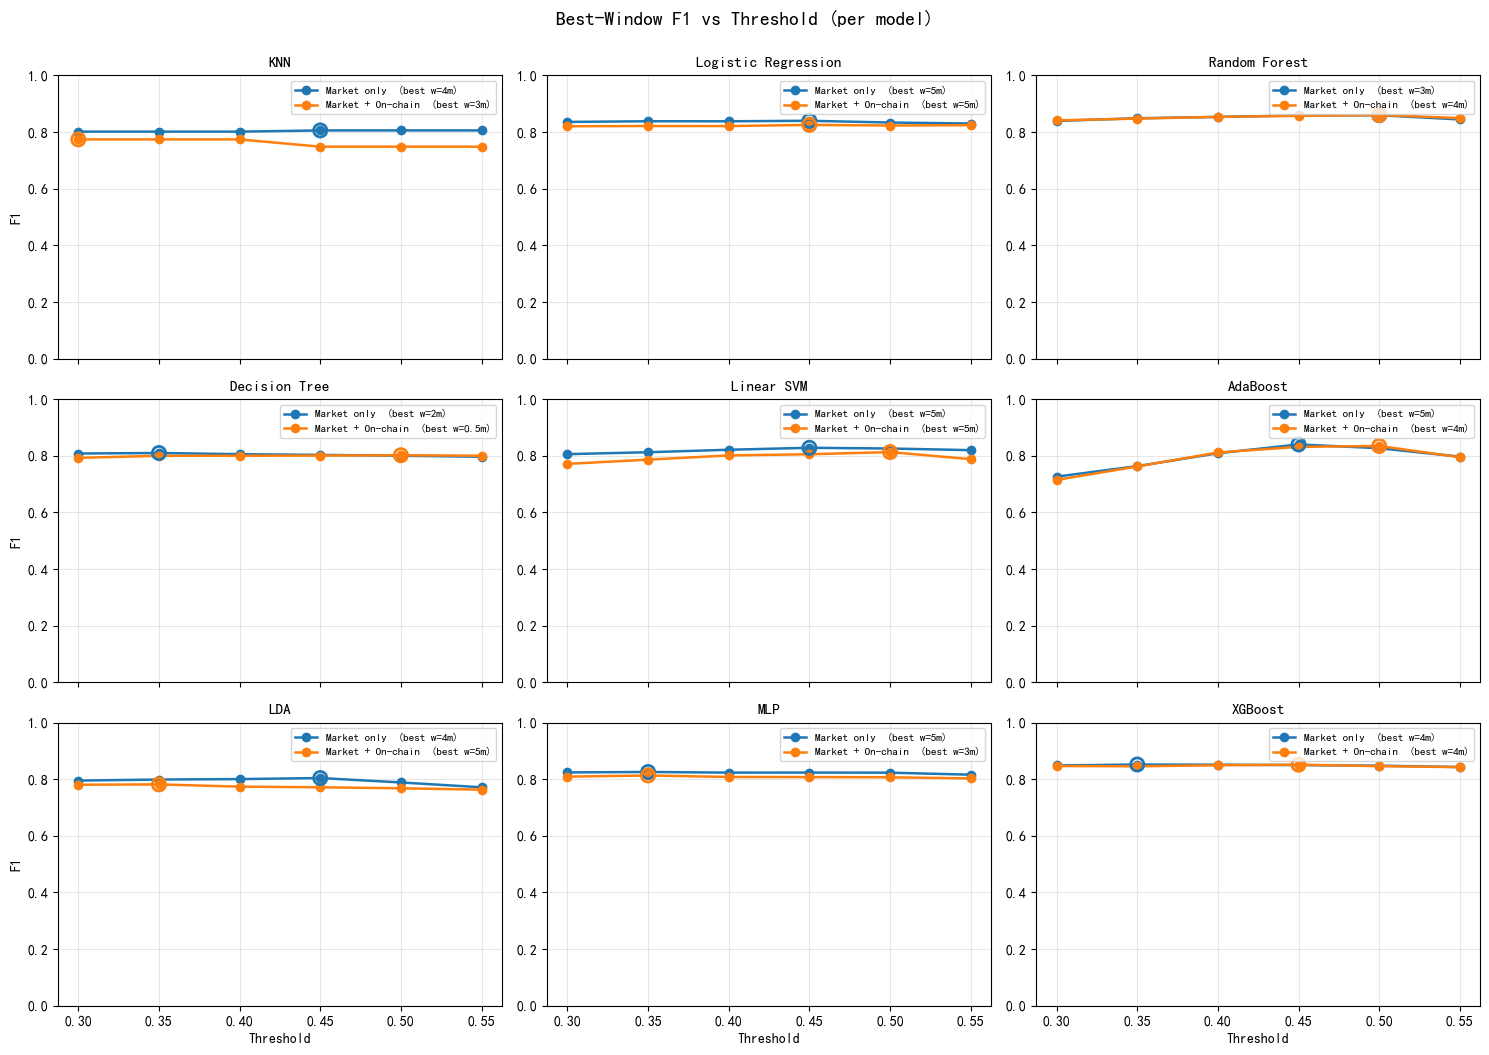

In [14]:
# ============================================================
# Block G4: 每个模型最优 window 下的 F1 vs threshold
# ============================================================
METRIC = 'F1'

models = list(MODEL_FACTORY.keys())
n_cols = 3
n_rows = int(np.ceil(len(models) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(5 * n_cols, 3.5 * n_rows),
                         sharex=True, squeeze=False)

feature_colors = {'Market only': '#1f77b4',
                  'Market + On-chain': '#ff7f0e'}

for idx, model in enumerate(models):
    ax = axes[idx // n_cols][idx % n_cols]

    for feature in ['Market only', 'Market + On-chain']:
        sub = sweep_df[(sweep_df['Model'] == model) &
                       (sweep_df['Feature Set'] == feature)]
        if sub.empty:
            continue

        best_w = (sub.groupby('Window')[METRIC].max()
                     .sort_values(ascending=False).index[0])

        s = (sub[sub['Window'] == best_w]
             .sort_values('Threshold')
             .set_index('Threshold')[METRIC])

        ax.plot(s.index, s.values, marker='o',
                color=feature_colors[feature],
                linewidth=1.8, markersize=6,
                label=f'{feature}  (best w={WINDOW_LABELS.get(best_w, f"{best_w}d")})')

        # 标记峰值
        if len(s) > 0 and not s.isna().all():
            t_best = s.idxmax()
            v_best = s.max()
            ax.scatter([t_best], [v_best], s=90, facecolors='none',
                       edgecolors=feature_colors[feature], linewidths=2, zorder=5)

    ax.set_title(model, fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc='best')
    ax.set_ylim(0, 1)

for k in range(len(models), n_rows * n_cols):
    axes[k // n_cols][k % n_cols].axis('off')

for ax in axes[-1, :]:
    ax.set_xlabel('Threshold')
for ax in axes[:, 0]:
    ax.set_ylabel(METRIC)

plt.suptitle(f'Best-Window F1 vs Threshold (per model)',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('bestwindow_f1_vs_threshold.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
# ============================================================
# Cell X: 用 best_df 里每个模型的最优配置预测 2026-10-14
#   - Feature Set / Window / Threshold 均取自 Cell 4 扫描结果
#   - 每个模型用自己 F1 最优的配置
# ============================================================
import pandas as pd
import numpy as np

# ---------- 0. 前置检查 ----------
if 'best_df' not in dir():
    raise RuntimeError("请先运行 Cell 4，得到 best_df")
if 'FEATURE_SETS' not in dir():
    raise RuntimeError("请先运行 Cell 3.5，得到 FEATURE_SETS")
if 'MODEL_FACTORY' not in dir():
    raise RuntimeError("请先运行 Cell 3，得到 MODEL_FACTORY")

TODAY_FILE  = 'today_data.xlsx'
TODAY_SHEET = 'today_data'
TARGET_DATE = pd.Timestamp('2026-10-14')

# ---------- 1. 读取 & 清洗 today_data ----------
today = pd.read_excel(TODAY_FILE, sheet_name=TODAY_SHEET)
print(f"[info] 以 Excel 读取 {TODAY_FILE} sheet='{TODAY_SHEET}'")

today.columns = [str(c).strip() for c in today.columns]
today = today.rename(columns={
    'miners_revenue（USD）':         'miners_revenue_usd',
    'total_transaction_fees（BTC）': 'total_transaction_fees_btc',
})
today['datetime'] = pd.to_datetime(today['datetime'], errors='coerce')
today = (today.dropna(subset=['datetime'])
              .sort_values('datetime')
              .drop_duplicates('datetime', keep='last')
              .reset_index(drop=True))


def _to_num(s):
    if s.dtype == object:
        s = s.astype(str).str.replace(',', '', regex=False)
    return pd.to_numeric(s, errors='coerce')


for col in num_cols:
    if col in today.columns:
        today[col] = _to_num(today[col])

if 'exchange_volume_usd' in today.columns:
    today.loc[today['exchange_volume_usd'] == 0, 'exchange_volume_usd'] = np.nan

print(f"[info] today_data 日期范围: "
      f"{today['datetime'].min().date()} ~ {today['datetime'].max().date()}, "
      f"记录数={len(today)}")

# ---------- 2. 特征构造（与 Cell 1 完全一致） ----------
today['target']        = (today['market_price_usd'] > today['market_price_usd'].shift(1)).astype(int)
today['return_1d']     = today['market_price_usd'].pct_change()
today['cum_return_7d'] = today['market_price_usd'].pct_change().rolling(7).sum()
today['volatility_7d'] = today['market_price_usd'].pct_change().rolling(7).std()
today['volume_change'] = np.log(today['exchange_volume_usd'] / today['exchange_volume_usd'].shift(1))

for src, dst in traditional_map.items():
    if src in today.columns:
        today[dst] = today[src].pct_change()
    else:
        print(f"[warn] today_data 缺少列: {src}")

for src, dst in crypto_map.items():
    if src in today.columns:
        today[dst] = today[src].pct_change()
    else:
        print(f"[warn] today_data 缺少列: {src}")

# mcap_ret：用价格变化近似（与训练保持一致）
if 'market_cap_usd' in today.columns:
    today['mcap_ret'] = today['market_cap_usd'].pct_change()
else:
    today['mcap_ret'] = today['market_price_usd'].pct_change()
   

today = today.set_index('datetime')
if TARGET_DATE not in today.index:
    raise ValueError(f"today_data 中不包含 {TARGET_DATE.date()}")

y_true_today = int(today.loc[TARGET_DATE, 'target'])

# ---------- 3. 从 best_df 取每个模型 F1 最优的配置 ----------
best_per_model = (best_df
    .sort_values('F1', ascending=False)
    .groupby('Model', as_index=False)
    .first()
)
print("\n===== 每个模型的最优配置（来自 Cell 4 扫描结果）=====")
print(best_per_model[['Model', 'Feature Set', 'Window', 'Threshold',
                     'Accuracy', 'F1', 'ROC-AUC']].round(4).to_string(index=False))

# ---------- 4. 用每个模型的最优配置预测 TARGET_DATE ----------
print(f"\n===== 开始预测 {TARGET_DATE.date()} =====")
all_preds = []

for _, cfg in best_per_model.iterrows():
    model_name   = cfg['Model']
    feature_name = cfg['Feature Set']
    window       = int(cfg['Window'])
    threshold    = float(cfg['Threshold'])

    if feature_name not in FEATURE_SETS:
        print(f"[skip] {model_name}|{feature_name}: FEATURE_SETS 中无此特征集")
        continue
    feat_cols = FEATURE_SETS[feature_name].columns.tolist()

    # 缺失特征兜底
    missing = [c for c in feat_cols if c not in today.columns]
    if missing:
        print(f"[skip] {model_name}|{feature_name}: today 缺列 {missing}")
        continue

    # 训练窗口：[TARGET_DATE - window - 1, TARGET_DATE - 1]
    # 每行 D 的特征 = D-1 的（shift(1)），标签 = D 的涨跌
    window_start = TARGET_DATE - pd.Timedelta(days=window + 1)
    window_end   = TARGET_DATE - pd.Timedelta(days=1)

    feat_shifted = today[feat_cols].shift(1)
    data = pd.concat([feat_shifted, today['target']], axis=1).dropna()
    mask = (data.index >= window_start) & (data.index <= window_end)

    X_train = data.loc[mask, feat_cols]
    y_train = data.loc[mask, 'target']
    X_pred  = feat_shifted.loc[[TARGET_DATE], feat_cols]

    min_train = max(3, int(window * 0.8))
    if len(X_train) < min_train:
        print(f"[skip] {model_name}|{feature_name}|w={window}: "
              f"训练样本 {len(X_train)} < {min_train}")
        continue
    if X_pred.isna().all(axis=1).any():
        print(f"[skip] {model_name}|{feature_name}: 预测样本特征全 NaN")
        continue

    try:
        model = MODEL_FACTORY[model_name]()
        model.fit(X_train, y_train)
        prob = model.predict_proba(X_pred)[0, 1]
        pred = int(prob >= threshold)
    except Exception as e:
        print(f"[skip] {model_name}|{feature_name}: 训练/预测失败 {e}")
        continue

    all_preds.append({
        'Model':       model_name,
        'Feature Set': feature_name,
        'Window':      window,
        'Threshold':   threshold,
        'N_train':     len(X_train),
        'P(up)':       prob,
        'Pred':        pred,
        'True':        y_true_today,
        'Correct':     int(pred == y_true_today),
    })

# ---------- 5. 汇总输出 ----------
if not all_preds:
    print("[warn] 没有任何模型成功预测，请检查 best_df / today_data 数据")
else:
    pred_df = (pd.DataFrame(all_preds)
                 .sort_values('P(up)', ascending=False)
                 .reset_index(drop=True))
    print(f"\n===== 各模型对 {TARGET_DATE.date()} 的预测（各自最优配置）=====")
    print(pred_df.round(4).to_string(index=False))

    # ---------- 6. Ensemble（软投票，阈值统一用 0.5） ----------
    avg_prob = float(pred_df['P(up)'].mean())
    avg_pred = int(avg_prob >= 0.5)
    avg_correct = float(pred_df['Correct'].mean())

    print(f"\n===== Ensemble 结果 =====")
    print(f"平均 P(up)            = {avg_prob:.4f}")
    print(f"Ensemble 预测方向      = {'上涨 ↑' if avg_pred == 1 else '下跌 ↓'}")
    print(f"真实方向               = {'上涨 ↑' if y_true_today == 1 else '下跌 ↓'}")
    print(f"各模型平均正确率        = {avg_correct:.2%}")
    print(f"Ensemble 是否正确       = {'✅' if avg_pred == y_true_today else '❌'}")

    # ---------- 7. 按正确数排序：如果想知道哪类特征集更靠谱 ----------
    stat = (pred_df.groupby('Feature Set')
                   .agg(n=('Model', 'count'),
                        correct=('Correct', 'sum'),
                        avg_p=('P(up)', 'mean'))
                   .round(4))
    print(f"\n===== 按特征集汇总 =====")
    print(stat.to_string())

[info] 以 Excel 读取 today_data.xlsx sheet='today_data'
[info] today_data 日期范围: 2020-01-01 ~ 2026-10-16, 记录数=2481

===== 每个模型的最优配置（来自 Cell 4 扫描结果）=====
              Model       Feature Set  Window  Threshold  Accuracy     F1  ROC-AUC
           AdaBoost       Market only     150       0.45    0.8200 0.8397   0.9060
      Decision Tree       Market only      60       0.35    0.7984 0.8093   0.8347
                KNN       Market only     120       0.45    0.7946 0.8059   0.8623
                LDA       Market only     120       0.45    0.7924 0.8039   0.8538
         Linear SVM       Market only     150       0.45    0.8125 0.8277   0.9021
Logistic Regression       Market only     150       0.45    0.8320 0.8401   0.9077
                MLP       Market only     150       0.35    0.8155 0.8254   0.8869
      Random Forest Market + On-chain     120       0.50    0.8559 0.8604   0.9270
            XGBoost       Market only     120       0.35    0.8417 0.8517   0.9125

===== 开始预测 2026-10-1

In [32]:
# ============================================================
# Cell Y (EN): Show + Export prediction results (English labels)
#   Depends on: Cell X (pred_df, y_true_today)
# ============================================================
import os
import pandas as pd
import numpy as np
from datetime import datetime
from IPython.display import display

# ---------- 0. Pre-checks ----------
for name in ['pred_df', 'y_true_today']:
    if name not in dir():
        raise RuntimeError(f"Please run Cell X first to produce '{name}'")

ts = datetime.now().strftime('%Y%m%d_%H%M')
target_str = pd.Timestamp('2026-10-14').strftime('%Y-%m-%d')
base_name  = f'prediction_{target_str}_{ts}'
os.makedirs('outputs', exist_ok=True)
xlsx_path  = os.path.join('outputs', f'{base_name}.xlsx')

# ---------- 1. Build tables ----------
DIR_MAP = {1: 'Up', 0: 'Down'}
RES_MAP = {1: 'Hit', 0: 'Miss'}

# Table 1: per-model prediction details
tbl_pred = pred_df.copy()
tbl_pred['Predicted Direction'] = tbl_pred['Pred'].map(DIR_MAP)
tbl_pred['Actual Direction']    = tbl_pred['True'].map(DIR_MAP)
tbl_pred['Result']              = tbl_pred['Correct'].map(RES_MAP)
tbl_pred = tbl_pred[[
    'Model', 'Feature Set', 'Window', 'Threshold',
    'N_train', 'P(up)',
    'Predicted Direction', 'Actual Direction', 'Result',
]]

# Table 2: aggregated by feature set
if 'stat' not in dir():
    stat = (pred_df.groupby('Feature Set')
                   .agg(n=('Model', 'count'),
                        correct=('Correct', 'sum'),
                        avg_p=('P(up)', 'mean'))
                   .round(4)
                   .reset_index())
stat = stat.rename(columns={
    'n': 'Models', 'correct': 'Hits', 'avg_p': 'Avg P(up)',
})
if 'Hit Rate' not in stat.columns:
    stat['Hit Rate'] = (stat['Hits'] / stat['Models']).round(4)
tbl_feat = stat

# Table 3: aggregated by model (single-day prediction = 1 row per model)
tbl_model = (pred_df.groupby('Model')
                    .agg(**{
                        'Feature Set':          ('Feature Set', 'first'),
                        'Window':               ('Window', 'first'),
                        'Threshold':            ('Threshold', 'first'),
                        'P(up)':                ('P(up)', 'first'),
                        'Predicted Direction':  ('Pred', lambda s: DIR_MAP[int(s.iloc[0])]),
                        'Result':               ('Correct', lambda s: RES_MAP[int(s.iloc[0])]),
                    })
                    .reset_index())

# Table 4: ensemble summary
avg_prob = float(pred_df['P(up)'].mean())
avg_pred = int(avg_prob >= 0.5)
tbl_ens = pd.DataFrame([{
    'Target Date':       target_str,
    'Models Used':       len(pred_df),
    'Avg P(up)':         round(avg_prob, 4),
    'Ensemble Direction': DIR_MAP[avg_pred],
    'Actual Direction':   DIR_MAP[y_true_today],
    'Ensemble Result':    RES_MAP[int(avg_pred == y_true_today)],
    'Avg Hit Rate':       round(float(pred_df['Correct'].mean()), 4),
}])

# Table 5: best-config provenance (from Cell 4)
try:
    tbl_cfg = (best_df.sort_values('F1', ascending=False)
                      .groupby('Model', as_index=False).first()
                      [['Model', 'Feature Set', 'Window', 'Threshold',
                        'Accuracy', 'F1', 'ROC-AUC']]
                      .round(4))
except Exception:
    tbl_cfg = None

# ---------- 2. Display in notebook (styled) ----------
def show_table(df, title, fmt=None):
    print(f"\n===== {title} =====")
    if df is None or len(df) == 0:
        print("(empty)")
        return
    styler = df.style
    if fmt:
        styler = styler.format(fmt)
    styler = (styler
              .set_properties(**{'text-align': 'center'})
              .set_table_styles([
                  {'selector': 'th', 'props': [
                      ('background', '#2c3e50'),
                      ('color', 'white'),
                      ('text-align', 'center')]},
              ]))
    display(styler)

show_table(tbl_pred,  'Per-Model Predictions (sorted by P(up))',
           {'P(up)': '{:.4f}'})
show_table(tbl_ens,   'Ensemble Summary',
           {'Avg P(up)': '{:.4f}', 'Avg Hit Rate': '{:.4f}'})
show_table(tbl_model, 'By Model (with best config)',
           {'P(up)': '{:.4f}'})
show_table(tbl_feat,  'By Feature Set',
           {'Avg P(up)': '{:.4f}', 'Hit Rate': '{:.4f}'})
if tbl_cfg is not None:
    show_table(tbl_cfg, 'Best Config Provenance (from Cell 4)',
               {'Accuracy': '{:.4f}', 'F1': '{:.4f}', 'ROC-AUC': '{:.4f}'})

# ---------- 3. Export to Excel (multi-sheet) ----------
with pd.ExcelWriter(xlsx_path, engine='openpyxl') as writer:
    tbl_ens.to_excel(writer,   sheet_name='00_Ensemble',      index=False)
    tbl_pred.to_excel(writer,  sheet_name='01_Predictions',   index=False)
    tbl_model.to_excel(writer, sheet_name='02_By_Model',      index=False)
    tbl_feat.to_excel(writer,  sheet_name='03_By_FeatureSet', index=False)
    if tbl_cfg is not None:
        tbl_cfg.to_excel(writer, sheet_name='04_Best_Configs', index=False)

print(f"\n[OK] Excel exported: {xlsx_path}")

# ---------- 4. Export CSV backups ----------
csv_paths = []
for name, tbl in [
    ('ensemble',    tbl_ens),
    ('predictions', tbl_pred),
    ('by_model',    tbl_model),
    ('by_feature',  tbl_feat),
]:
    if tbl is None or len(tbl) == 0:
        continue
    p = os.path.join('outputs', f'{base_name}_{name}.csv')
    tbl.to_csv(p, index=False, encoding='utf-8-sig')
    csv_paths.append(p)

if tbl_cfg is not None:
    p = os.path.join('outputs', f'{base_name}_best_configs.csv')
    tbl_cfg.to_csv(p, index=False, encoding='utf-8-sig')
    csv_paths.append(p)

print(f"[OK] CSV backups exported: {len(csv_paths)} files")
for p in csv_paths:
    print(f"     - {p}")


===== Per-Model Predictions (sorted by P(up)) =====


,Model,Feature Set,Window,Threshold,N_train,P(up),Predicted Direction,Actual Direction,Result
0,Decision Tree,Market only,60,0.350000,61,1.0000,Up,Up,Hit
1,KNN,Market only,120,0.450000,121,1.0000,Up,Up,Hit
2,XGBoost,Market only,120,0.350000,121,0.9918,Up,Up,Hit
3,Logistic Regression,Market only,150,0.450000,151,0.9771,Up,Up,Hit
4,LDA,Market only,120,0.450000,121,0.9277,Up,Up,Hit
5,MLP,Market only,150,0.350000,151,0.8925,Up,Up,Hit
6,Random Forest,Market + On-chain,120,0.500000,121,0.8923,Up,Up,Hit
7,Linear SVM,Market only,150,0.450000,151,0.8055,Up,Up,Hit
8,AdaBoost,Market only,150,0.450000,151,0.6926,Up,Up,Hit



===== Ensemble Summary =====


,Target Date,Models Used,Avg P(up),Ensemble Direction,Actual Direction,Ensemble Result,Avg Hit Rate
0,2026-10-14,9,0.9088,Up,Up,Hit,1.0000



===== By Model (with best config) =====


...


===== By Feature Set =====


,Models,Hits,Avg P(up),Hit Rate
Feature Set,,,,
Market + On-chain,1,1,0.8923,1.0000
Market only,8,8,0.9109,1.0000



===== Best Config Provenance (from Cell 4) =====


,Model,Feature Set,Window,Threshold,Accuracy,F1,ROC-AUC
0,AdaBoost,Market only,150,0.450000,0.8200,0.8397,0.9060
1,Decision Tree,Market only,60,0.350000,0.7984,0.8093,0.8347
2,KNN,Market only,120,0.450000,0.7946,0.8059,0.8623
3,LDA,Market only,120,0.450000,0.7924,0.8039,0.8538
4,Linear SVM,Market only,150,0.450000,0.8125,0.8277,0.9021
5,Logistic Regression,Market only,150,0.450000,0.8320,0.8401,0.9077
6,MLP,Market only,150,0.350000,0.8155,0.8254,0.8869
7,Random Forest,Market + On-chain,120,0.500000,0.8559,0.8604,0.9270
8,XGBoost,Market only,120,0.350000,0.8417,0.8517,0.9125



[OK] Excel exported: outputs\prediction_2026-10-14_20261017_1038.xlsx
[OK] CSV backups exported: 5 files
     - outputs\prediction_2026-10-14_20261017_1038_ensemble.csv
     - outputs\prediction_2026-10-14_20261017_1038_predictions.csv
     - outputs\prediction_2026-10-14_20261017_1038_by_model.csv
     - outputs\prediction_2026-10-14_20261017_1038_by_feature.csv
     - outputs\prediction_2026-10-14_20261017_1038_best_configs.csv
